# Validation of selected cell type levels

In this Notebook we assess whether our labels are too coarse or too fine.
Too fine: assessment of mapping uncertainty in the labels for the whole extension
Too coarse: </br> 1) Comparison of score distributions in subtypes </br> 2) Changes of uncertainty when increasing level

In [3]:
# import os
# os.chdir('../')
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [4]:
import sys
sys.path.insert(0,"C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\Mapping_package" )

In [5]:
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scipy

import pandas as pd
import datetime
import statsmodels.stats.multitest as mtc
import json
import timeit
import seaborn as sb
from MappingAssessment import MapAnalyzer, Plotter


In [6]:
workspace = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA"

In [141]:
adata= sc.read(f'{workspace}\\Adatas\\HLCA_full_tranf.h5ad')

In [111]:
adata.obs["query_or_reference"]="query"
adata.obs.loc[adata.obs.core_or_extension=="core","query_or_reference"]="reference"

In [117]:
adata.obs.dataset.cat.categories

Index(['Banovich_Kropski_2020', 'Barbry_Leroy_2020',
       'Jain_Misharin_2021_10Xv1', 'Jain_Misharin_2021_10Xv2', 'Kaminski_2020',
       'Krasnow_2020', 'Lafyatis_Rojas_2019_10Xv1',
       'Lafyatis_Rojas_2019_10Xv2', 'Meyer_2019', 'Misharin_2021',
       'Misharin_Budinger_2018', 'Nawijn_2021', 'Seibold_2020_10Xv2',
       'Seibold_2020_10Xv3', 'Teichmann_Meyer_2019'],
      dtype='object')

### Preprocessing

We transfer the labels from reference to the whole extension to validate our choice of cell type labels. We want to make sure that the transfer uncertainty < 0.3. This makes sure that the labels are not too fine.

In [142]:
adata_handler = MapAnalyzer.AdataHandler(
    adata,
    workspace=f"{workspace}\\MapAnalyzer_Results_3.0\\",
    ident=ident+"\\",  # folder that indentifies this workpartition
    log=True,  # create a logfile
)

Logger directory already exists


In [138]:
# Plotter object for the plots
plotter = Plotter.MapPlot(workspace=f"{adata_handler.workspace}/{ident}")

In [19]:
adata_handler.set_cell_type_levels(1,['ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5'],"ann_finest_level","nan")

2023-05-22 21:32:17.696019	starting with cell labels:
['AT0', 'AT1', 'AT2', 'AT2 proliferating', 'Adventitial fibroblasts', 'Alveolar Mph CCL3+', 'Alveolar Mph MT-positive', 'Alveolar Mph proliferating', 'Alveolar fibroblasts', 'Alveolar macrophages', 'B cells', 'Basal resting', 'CD4 T cells', 'CD8 T cells', 'Classical monocytes', 'Club (nasal)', 'Club (non-nasal)', 'DC1', 'DC2', 'Deuterosomal', 'EC aerocyte capillary', 'EC arterial', 'EC general capillary', 'EC venous pulmonary', 'EC venous systemic', 'Goblet (bronchial)', 'Goblet (nasal)', 'Goblet (subsegmental)', 'Hematopoietic stem cells', 'Hillock-like', 'Interstitial Mph perivascular', 'Ionocyte', 'Lymphatic EC differentiating', 'Lymphatic EC mature', 'Lymphatic EC proliferating', 'Mast cells', 'Mesothelium', 'Migratory DCs', 'Monocyte-derived Mph', 'Multiciliated (nasal)', 'Multiciliated (non-nasal)', 'Myofibroblasts', 'NK cells', 'Neuroendocrine', 'Non-classical monocytes', 'Peribronchial fibroblasts', 'Pericytes', 'Plasma cell

C:\Users\49176\anaconda3\envs\metricselection\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2023-05-22 21:33:39.692279	Iteration 1

2023-05-22 21:34:44.208419	merging related cell types ['Alveolar Mph CCL3+', 'Alveolar Mph MT-positive', 'Alveolar Mph proliferating']  to patental cell type Alveolar macrophages

2023-05-22 21:34:44.849971	merging related cell types ['Adventitial fibroblasts', 'Alveolar fibroblasts', 'Peribronchial fibroblasts', 'Pericytes', 'Subpleural fibroblasts']  to patental cell type Fibroblasts

2023-05-22 21:34:45.114705	merging related cell types ['CD4 T cells', 'CD8 T cells', 'T cells proliferating']  to patental cell type T cell lineage

2023-05-22 21:34:45.355718	merging related cell types ['DC1', 'DC2', 'Migratory DCs', 'Plasmacytoid DCs']  to patental cell type Dendritic cells

2023-05-22 21:34:45.570567	merging related cell types ['EC aerocyte capillary', 'EC general capillary']  to patental cell type EC capillary

2023-05-22 21:34:45.774159	merging related cell types ['EC venous pulmonary', 'EC venous systemic']  to patental cell type EC venous



In [21]:
adata= adata_handler.get_adata()

In [8]:
adata

AnnData object with n_obs × n_vars = 2282447 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'ti

Transfer celltype labels from reference data to query cells. Save adata for later.

In [22]:
adata_handler.transfer_labels(transfer_columns=["cell_label"],pickle=False)

2023-05-22 21:40:00.374526	Transferring labels...
2023-05-22 21:40:02.616139	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-05-22 21:40:08.417004	Transfer Labels
2023-05-22 21:40:08.432625	transferring cell_label
finished!


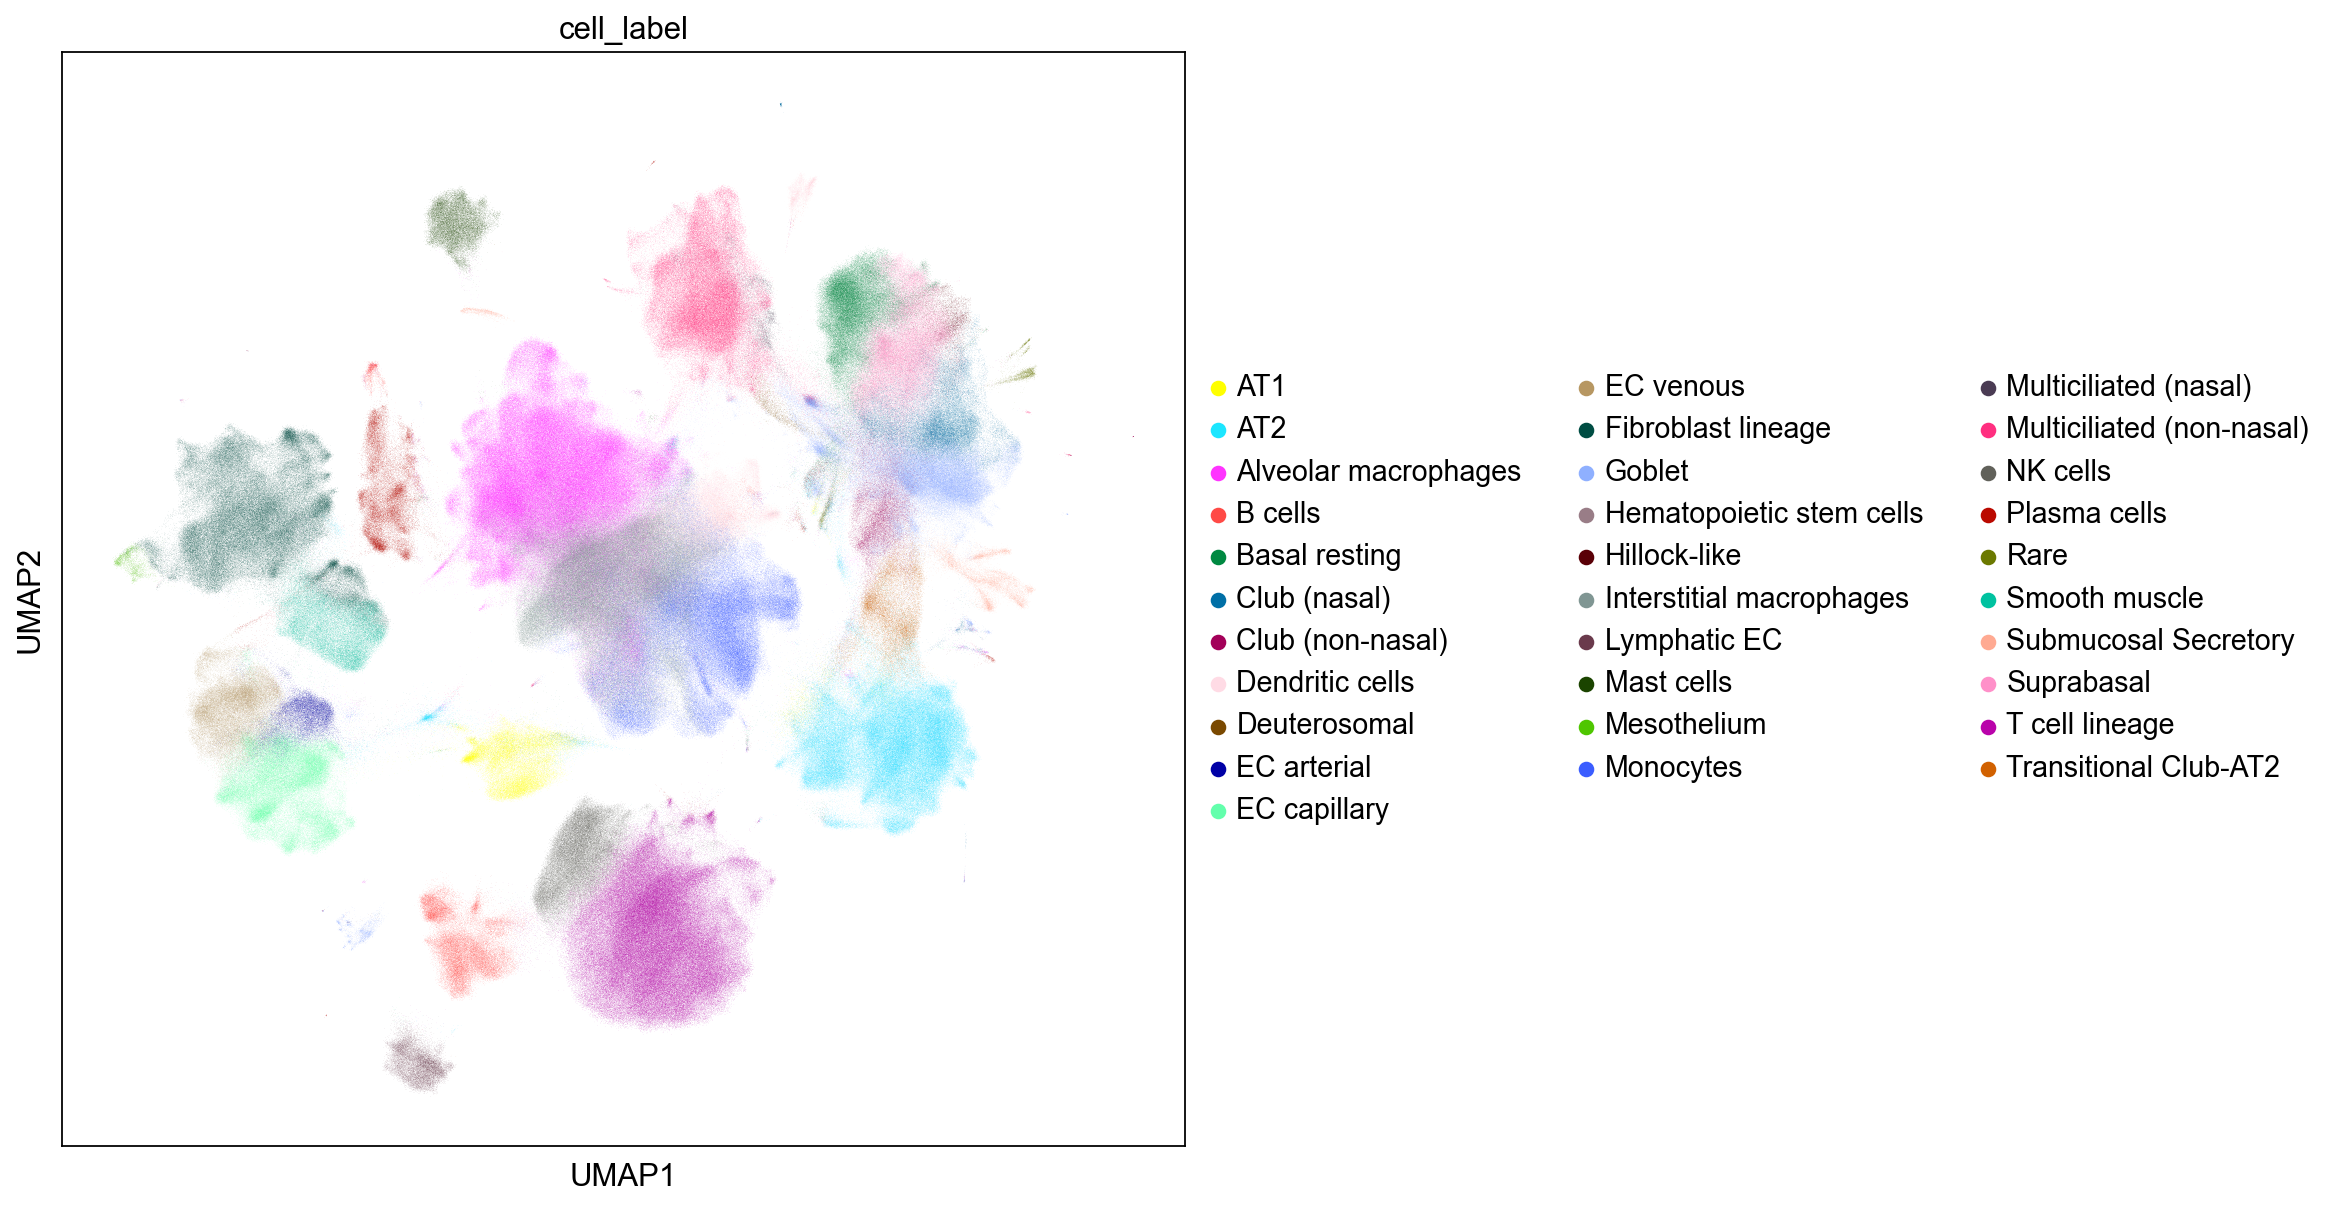

In [23]:
sc.pl.umap(adata,color="cell_label")

In [24]:
adata.obs[["query_or_reference","cell_label"]]

,query_or_reference,cell_label
CGATGTAAGTTACGGG_SC10,reference,Alveolar macrophages
cc05p_CATGCCTGTGTGCCTG_carraro_csmc,query,Suprabasal
ATTCTACCAAGGTTCT_HD68,reference,EC capillary
D062_TGACCCTTCAAACCCA-sub_wang_sub_batch3,query,Fibroblast lineage
muc9826_GTCGTGAGAGGA_mayr,query,Multiciliated (non-nasal)
...,...,...
TTGTGGATCGTTCCTG_5-PX5-sub_mould,query,Alveolar macrophages
TCAGGATCAAGACGTG_F02526,reference,Multiciliated (non-nasal)
CAACCTCTCATGTAGC-WSSS8015042-0_meyer_unpubl,query,Alveolar macrophages
022C-b_GGATGTTTCCAAGTAC_adams,query,Alveolar macrophages


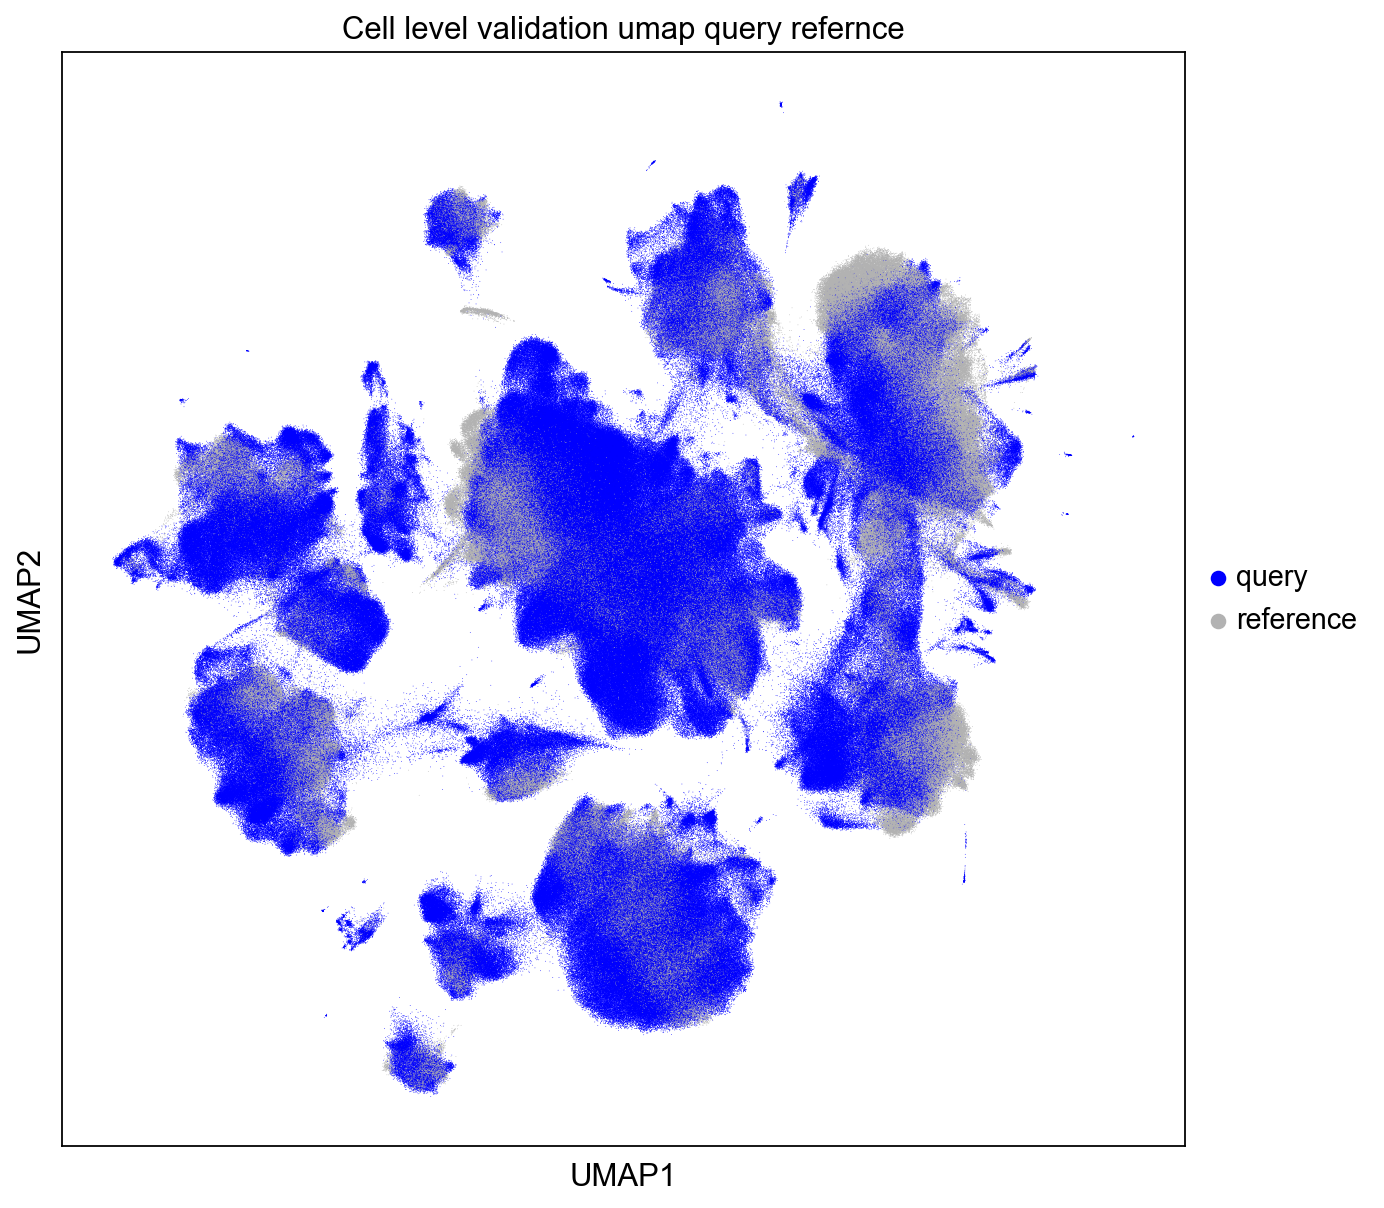

In [25]:
plotter.umap_query_reference(
    adata, color_query=query_color, title_stub=ident, save=False
)

In [26]:
#adata.write(f'{workspace}\\Adatas\\HLCA_full_tranf.h5ad')

## Too fine?

After label transfer we group the cell types and get their mean uncertainty. 

In [43]:
group = adata.obs.groupby("cell_label").agg({"cell_label_uncert":("mean","std")}).reset_index(drop=False)

In [44]:
group

cell_label cell_label_uncert          
                                           mean       std
0                         AT1          0.080957  0.153246
1                         AT2          0.055637  0.134440
2        Alveolar macrophages          0.114055  0.164717
3                     B cells          0.029466  0.096276
4               Basal resting          0.185696  0.192220
5                Club (nasal)          0.297912  0.197115
6            Club (non-nasal)          0.288004  0.192273
7             Dendritic cells          0.188990  0.207837
8                Deuterosomal          0.131681  0.185196
9                 EC arterial          0.143321  0.184628
10               EC capillary          0.088071  0.147224
11                  EC venous          0.096681  0.156274
12         Fibroblast lineage          0.033748  0.096518
13                     Goblet          0.195535  0.188101
14   Hematopoietic stem cells          0.496777  0.148237
15               Hillock-like          0.341038  0.196806
16   Interstitial macrophages          0.264907  0.167862
17               Lymphatic EC          0.022861  0.094324
18                 Mast cells          0.016249  0.078934
19                Mesothelium          0.093256  0.149410
20                  Monocytes          0.185765  0.198368
21      Multiciliated (nasal)          0.345257  0.134429
22  Multiciliated (non-nasal)          0.045471  0.110612
23                   NK cells          0.084147  0.135551
24               Plasma cells          0.033240  0.111027
25                       Rare          0.137328  0.210451
26              Smooth muscle          0.108675  0.154029
27       Submucosal Secretory          0.053637  0.131890
28                 Suprabasal          0.231320  0.187170
29             T cell lineage          0.033137  0.097648
30      Transitional Club-AT2          0.187454  0.195505

now we filter the cell types that end up in the analysis:

In [40]:
file = open(f"{workspace}\\MapAnalyzer_Results_3.0\\celltypes.txt")
ct = []
for line in file:
    ct.append(line.strip("\n"))

In [41]:
ct

['AT2',
 'Alveolar macrophages',
 'Dendritic cells',
 'EC arterial',
 'EC venous',
 'Fibroblast lineage',
 'Goblet',
 'Interstitial macrophages',
 'Mast cells',
 'Monocytes',
 'Multiciliated (non-nasal)',
 'NK cells',
 'Suprabasal',
 'T cell lineage',
 'Transitional Club-AT2']

In [47]:
group[group.cell_label.isin(ct)].sort_values(("cell_label_uncert","mean"))

cell_label cell_label_uncert          
                                           mean       std
18                 Mast cells          0.016249  0.078934
29             T cell lineage          0.033137  0.097648
12         Fibroblast lineage          0.033748  0.096518
22  Multiciliated (non-nasal)          0.045471  0.110612
1                         AT2          0.055637  0.134440
23                   NK cells          0.084147  0.135551
11                  EC venous          0.096681  0.156274
2        Alveolar macrophages          0.114055  0.164717
9                 EC arterial          0.143321  0.184628
20                  Monocytes          0.185765  0.198368
30      Transitional Club-AT2          0.187454  0.195505
7             Dendritic cells          0.188990  0.207837
13                     Goblet          0.195535  0.188101
28                 Suprabasal          0.231320  0.187170
16   Interstitial macrophages          0.264907  0.167862

The uncertainties are mostly < 0.2 and only Suprabasal and Interstitial macrophages	violate that -> Not too fine

## Too coarse?

Next we want to see wether our labels could be too coarse. For that we obtain the scores for each cell type and dataset from the reference.

In [75]:
file = open(f"{workspace}\\MapAnalyzer_Results_3.0\\celltypes.txt")
ct = []
for line in file:
    ct.append(line.strip("\n"))

In [1]:
#set parameters here
dataset = 'X'
ident = 'Cell level validation'
query_color = "Blue"
condition = "X"
exclude = []

In [7]:
adata= sc.read(f'{workspace}\\Adatas\\HLCA_full_tranf.h5ad')

In [8]:
adata = adata[(adata.obs.core_or_extension=="core")|((adata.obs.dataset==dataset))]

In [9]:
adata_handler = MapAnalyzer.AdataHandler(
    adata,
    workspace=f"{workspace}\\MapAnalyzer_Results_3.0\\",
    ident=ident+"\\",  # folder that indentifies this workpartition
    log=True,  # create a logfile
)

Logger directory already exists


In [10]:
adata_handler.standarize_columns(
    condition_name=condition,  # condition name we want to distinguish
    query_dataset=dataset,  # query datasets
    cell_type_col=None,  # column name denoting celltype, none if no unified column
    dataset_col="dataset",  # column name denoting dataset
    sample_col="sample",  # column name danoting sample
    condition_col="lung_condition",  # column name denoting condition (abovementioned)
    subject_col="donor_id",  # column name denoting patients, subjects or donors
    disease_exclude=exclude,  # diseases to exclude from analysis
)

2023-05-23 21:18:29.647350	Standarizing columns...
2023-05-23 21:18:33.071210	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'
2023-05-23 21:18:33.074204	Finished column standarizing



In [11]:
scorer = MapAnalyzer.MappingScoring(adata_handler)

Logger directory already exists
2023-05-23 21:18:33.100408	Checking columns...


In [12]:
scorer.add_baseline(
    f"{scorer.workspace}\\baseline.csv",
    f"{workspace}\\MapAnalyzer_Results_3.0\\celltypes.txt",
)

2023-05-23 21:18:35.493378	Baseline consists of following cell types:

2023-05-23 21:18:35.496390	AT2


2023-05-23 21:18:35.496390	Alveolar macrophages


2023-05-23 21:18:35.496390	Dendritic cells


2023-05-23 21:18:35.496390	EC arterial


2023-05-23 21:18:35.496390	EC venous


2023-05-23 21:18:35.496390	Fibroblast lineage


2023-05-23 21:18:35.496390	Goblet


2023-05-23 21:18:35.496390	Interstitial macrophages


2023-05-23 21:18:35.496390	Mast cells


2023-05-23 21:18:35.496390	Monocytes


2023-05-23 21:18:35.497364	Multiciliated (non-nasal)


2023-05-23 21:18:35.497364	NK cells


2023-05-23 21:18:35.497364	Suprabasal


2023-05-23 21:18:35.497364	T cell lineage


2023-05-23 21:18:35.497364	Transitional Club-AT2




In [13]:
adata = scorer.get_adata()

In [14]:
adata

AnnData object with n_obs × n_vars = 584944 × 30
    obs: 'suspension_type', 'subject_ID', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 't

In [23]:
scorer.add_transformation(f"{workspace}\\MapAnalyzer_Results_3.0\\transformation.csv")

In [24]:
trans= scorer.transformation

Here we compare the distributions of sublevels. First visually then also via KS-test comparing all the subtypes with the most prevalent subtype.

                     percent
ann_finest_level            
AT2                98.436023
AT2 proliferating   1.563977


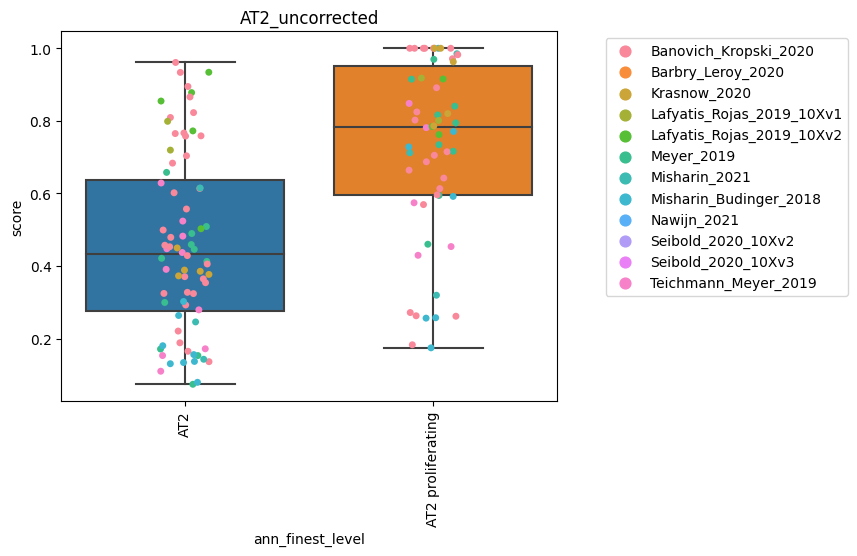

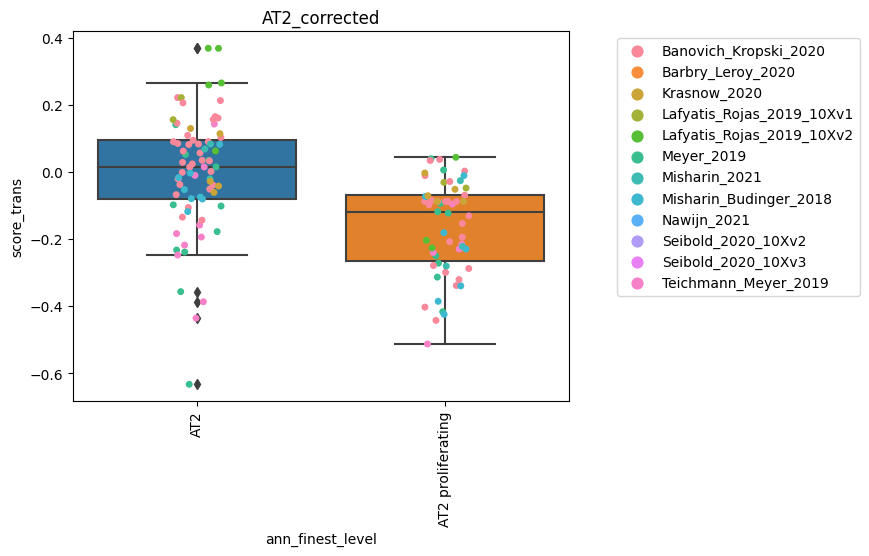

AT2 as reference
           cell type  p-value
0  AT2 proliferating      0.0

                              percent
ann_finest_level                     
Alveolar Mph CCL3+          10.232694
Alveolar Mph MT-positive     1.526340
Alveolar Mph proliferating   1.346173
Alveolar macrophages        86.894793


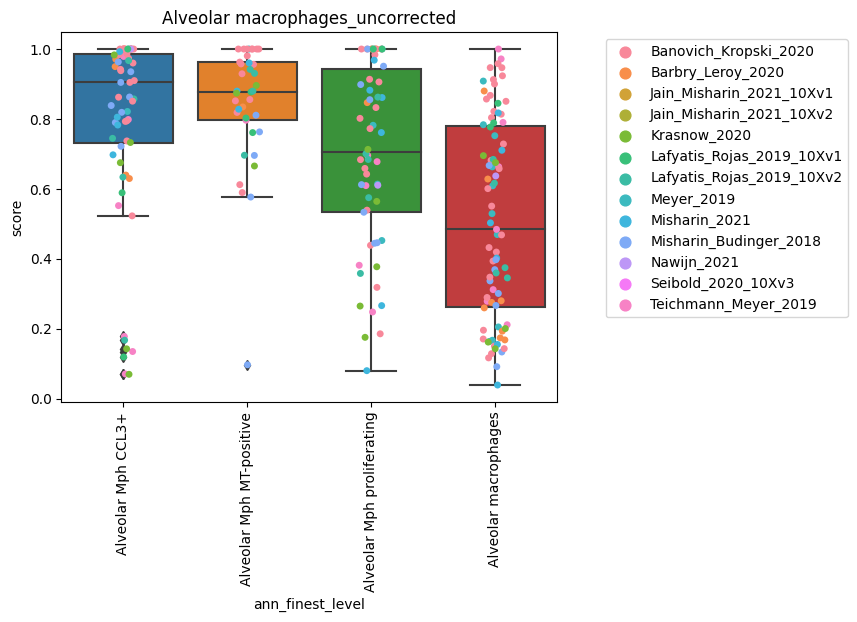

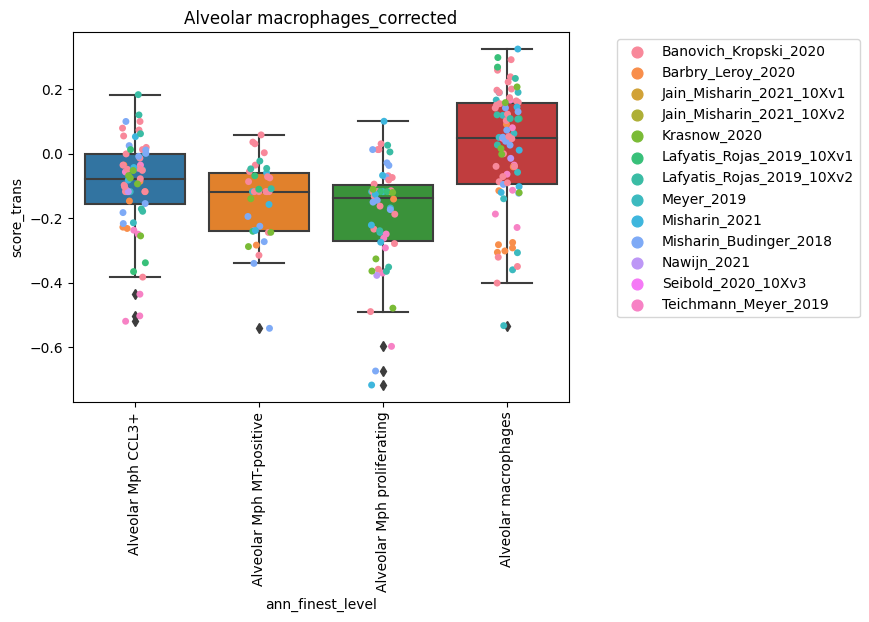

Alveolar macrophages as reference
                    cell type  p-value
0          Alveolar Mph CCL3+      0.0
1    Alveolar Mph MT-positive      0.0
2  Alveolar Mph proliferating      0.0

                    percent
ann_finest_level           
DC1                3.120457
DC2               88.506638
Migratory DCs      3.023549
Plasmacytoid DCs   5.349356


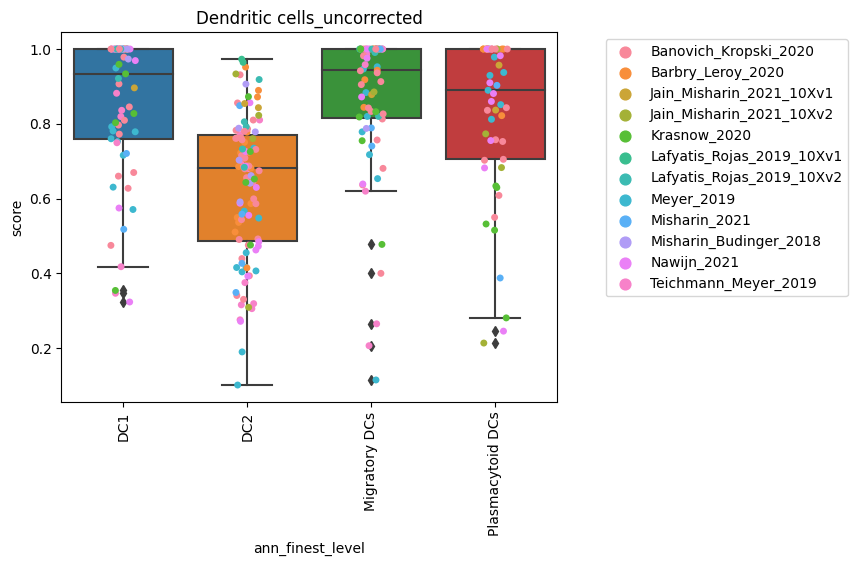

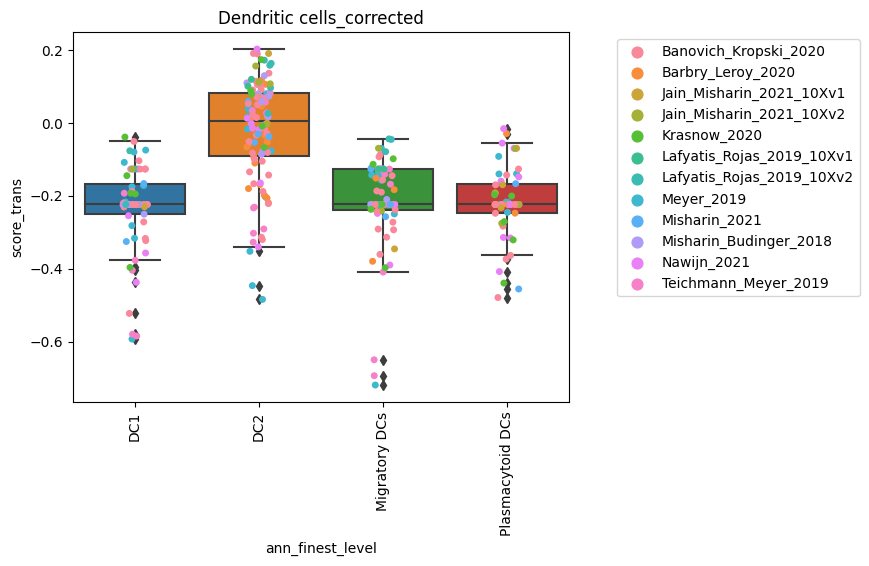

DC2 as reference
          cell type  p-value
0               DC1      0.0
1     Migratory DCs      0.0
2  Plasmacytoid DCs      0.0

                  percent
ann_finest_level         
EC arterial         100.0


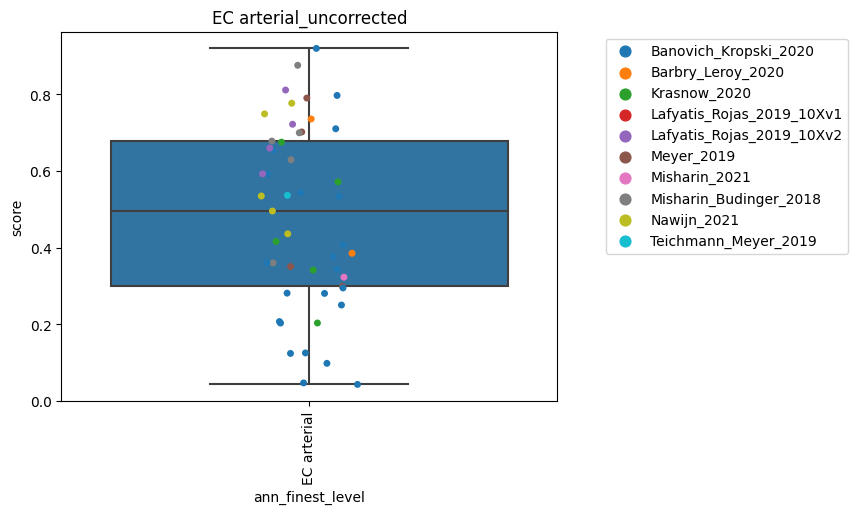

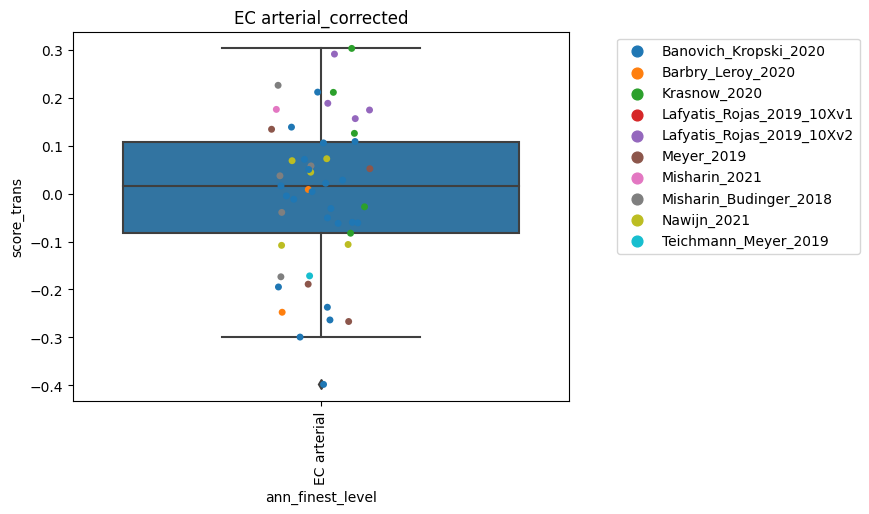

EC arterial as reference
Empty DataFrame
Columns: [cell type, p-value]
Index: []

                       percent
ann_finest_level              
EC venous pulmonary  49.464355
EC venous systemic   50.535645


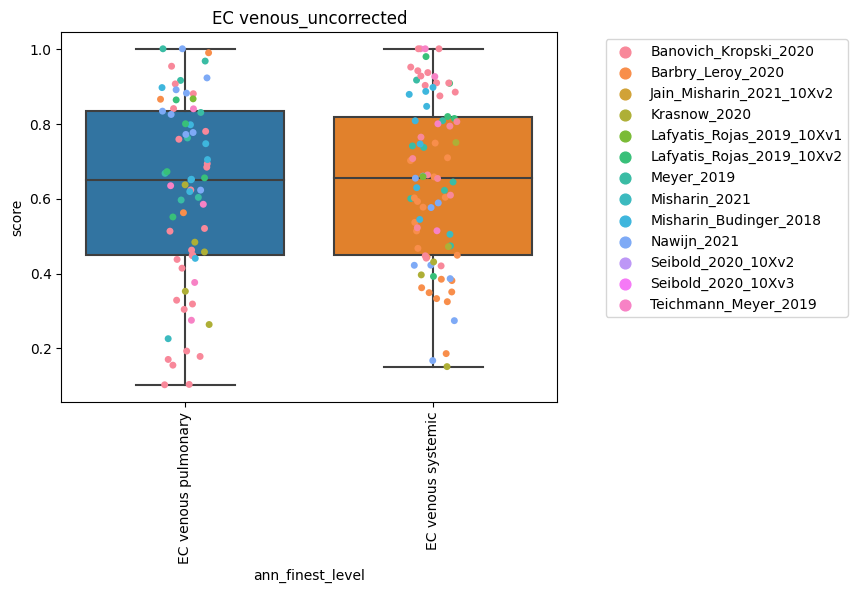

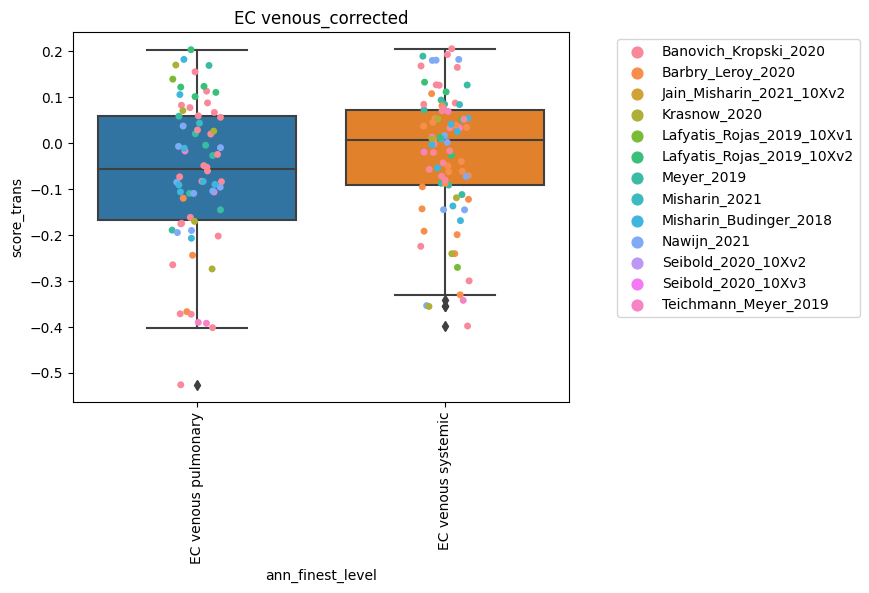

EC venous systemic as reference
             cell type  p-value
0  EC venous pulmonary   0.1021

                             percent
ann_finest_level                    
Adventitial fibroblasts    48.914692
Alveolar fibroblasts       24.559242
Myofibroblasts              3.393365
Peribronchial fibroblasts   7.454976
Pericytes                  14.369668
Subpleural fibroblasts      1.308057


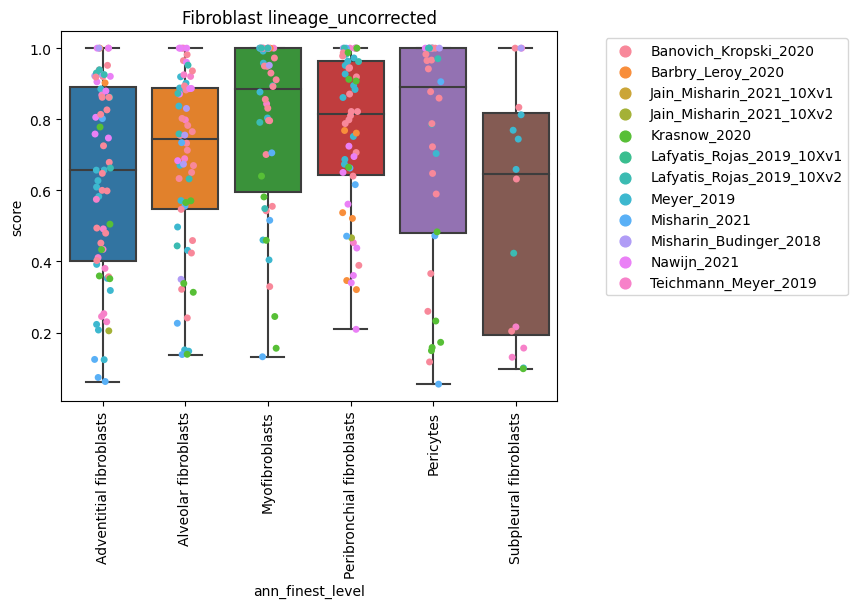

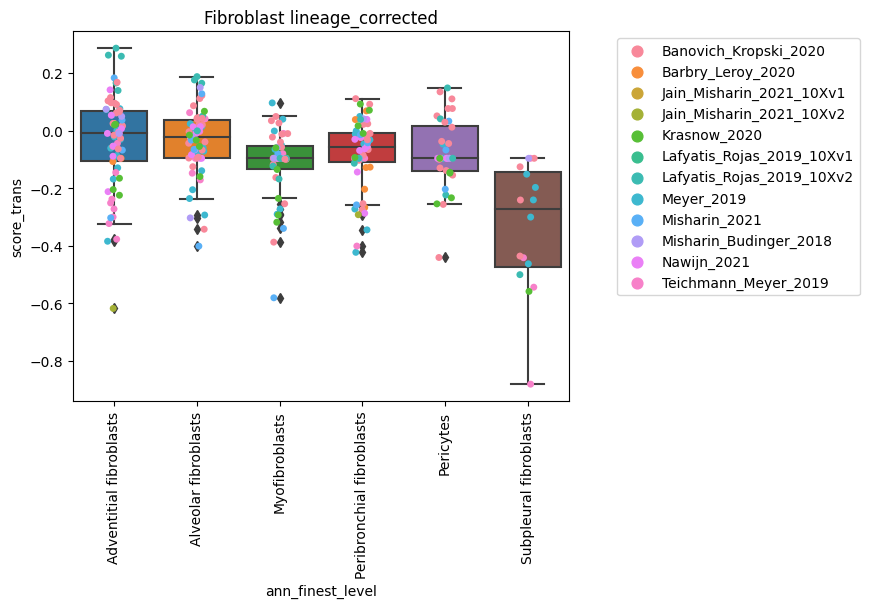

Adventitial fibroblasts as reference
                   cell type  p-value
0       Alveolar fibroblasts   0.4269
1             Myofibroblasts   0.0005
2  Peribronchial fibroblasts   0.0357
3                  Pericytes   0.0133
4     Subpleural fibroblasts   0.0000

                         percent
ann_finest_level                
Goblet (bronchial)      4.340932
Goblet (nasal)         93.142887
Goblet (subsegmental)   2.516181


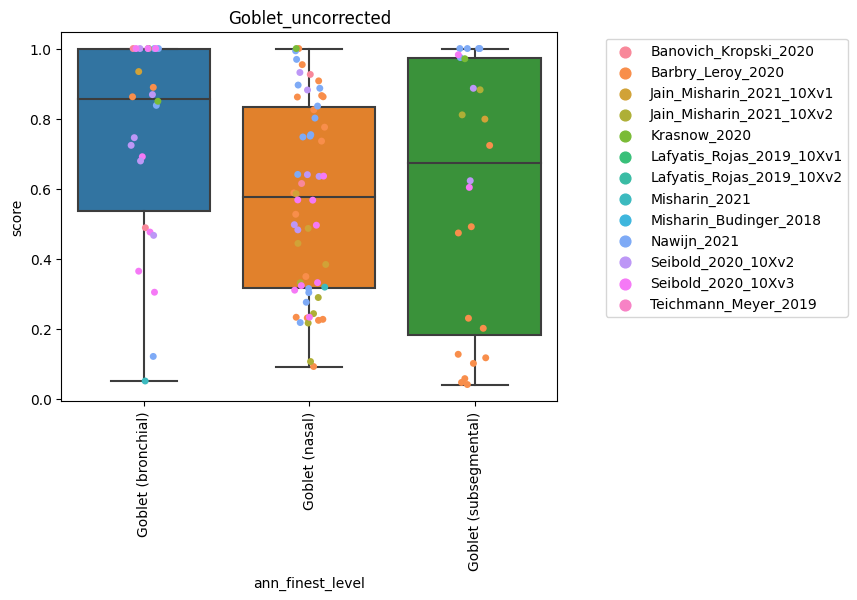

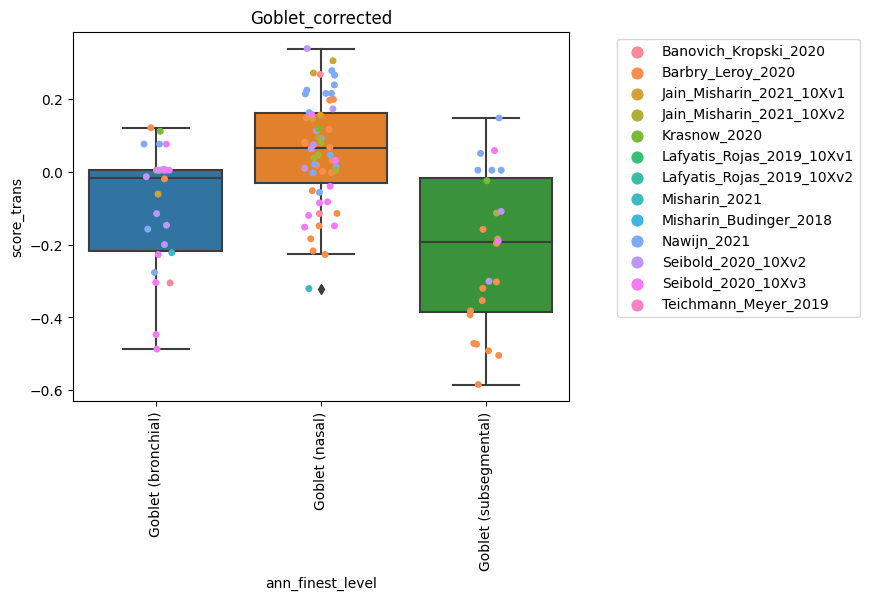

Goblet (nasal) as reference
               cell type  p-value
0     Goblet (bronchial)   0.0003
1  Goblet (subsegmental)   0.0000

                                 percent
ann_finest_level                        
Interstitial Mph perivascular  14.548262
Monocyte-derived Mph           85.451738


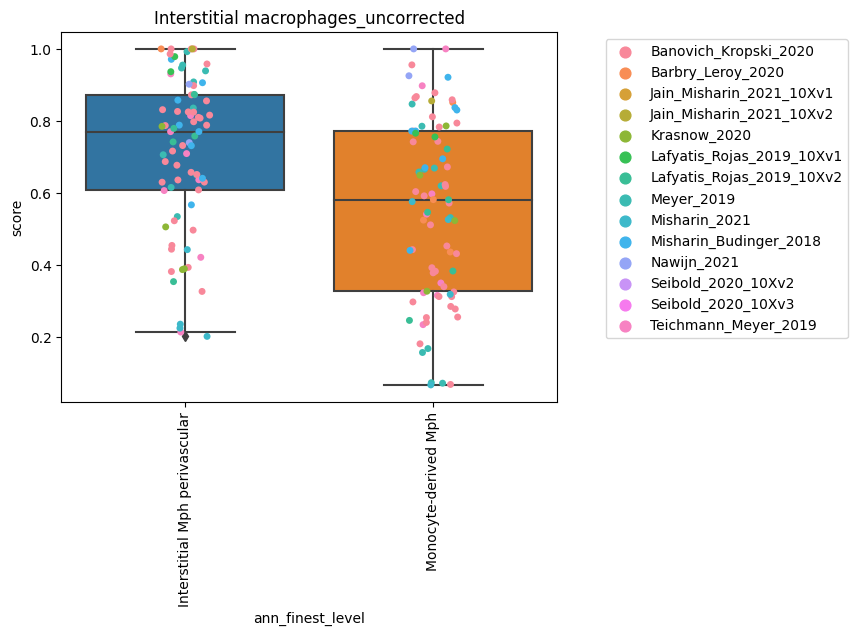

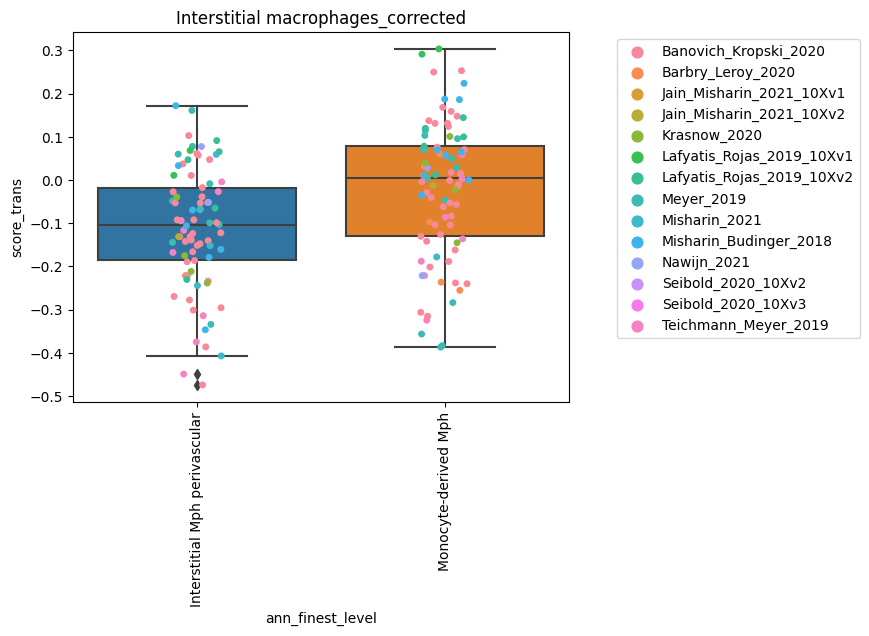

Monocyte-derived Mph as reference
                       cell type  p-value
0  Interstitial Mph perivascular   0.0002

                  percent
ann_finest_level         
Mast cells          100.0


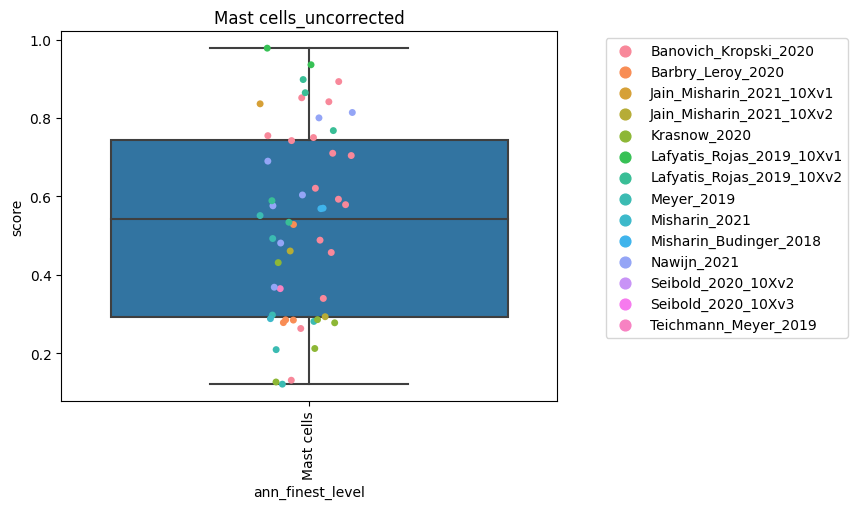

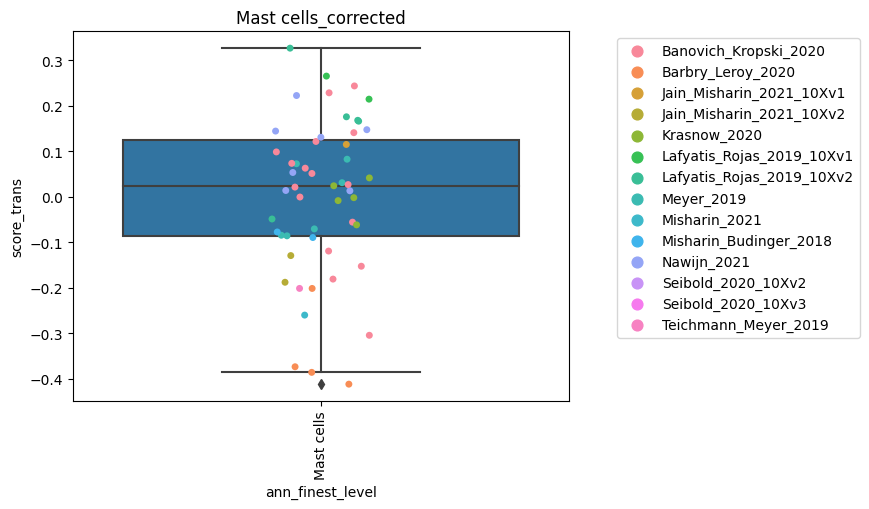

Mast cells as reference
Empty DataFrame
Columns: [cell type, p-value]
Index: []

                           percent
ann_finest_level                  
Classical monocytes      66.700592
Non-classical monocytes  33.299408


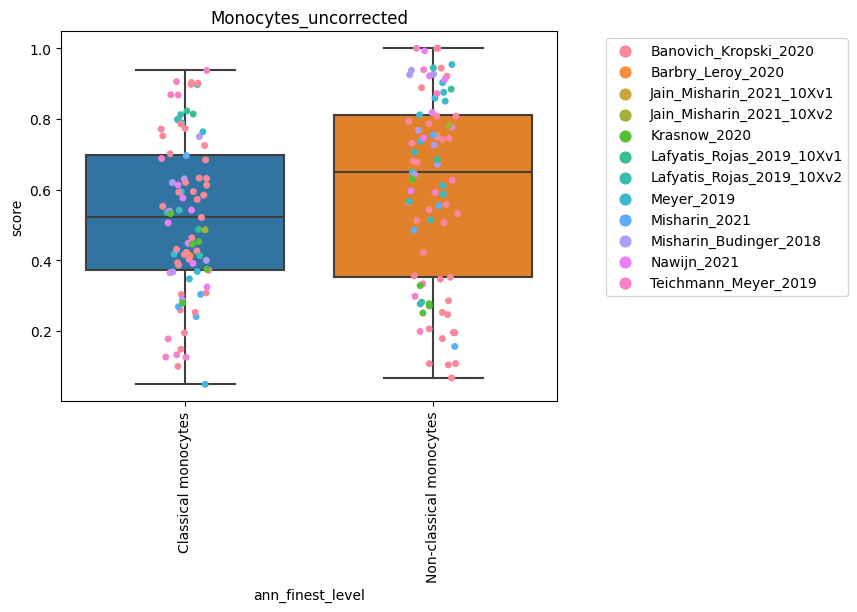

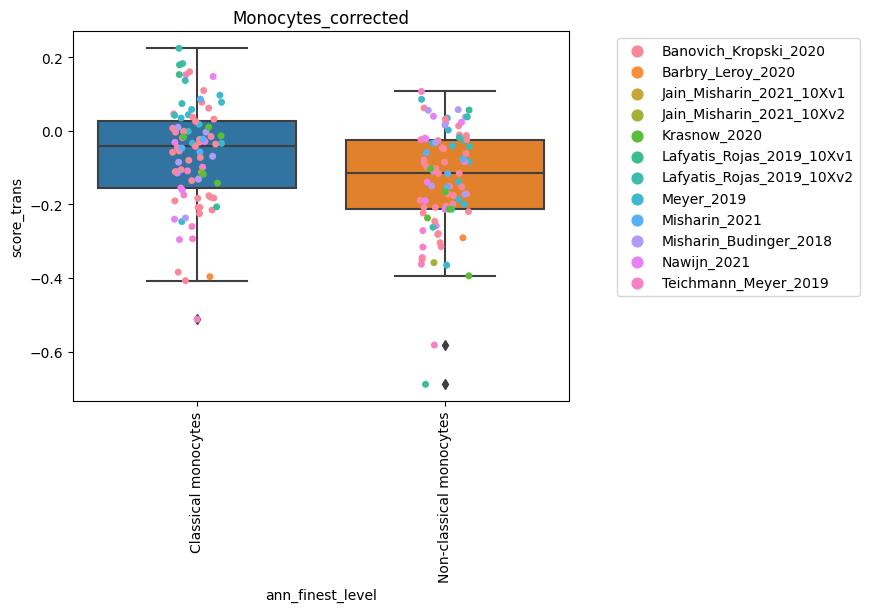

Classical monocytes as reference
                 cell type  p-value
0  Non-classical monocytes   0.0343

                           percent
ann_finest_level                  
Multiciliated (non-nasal)    100.0


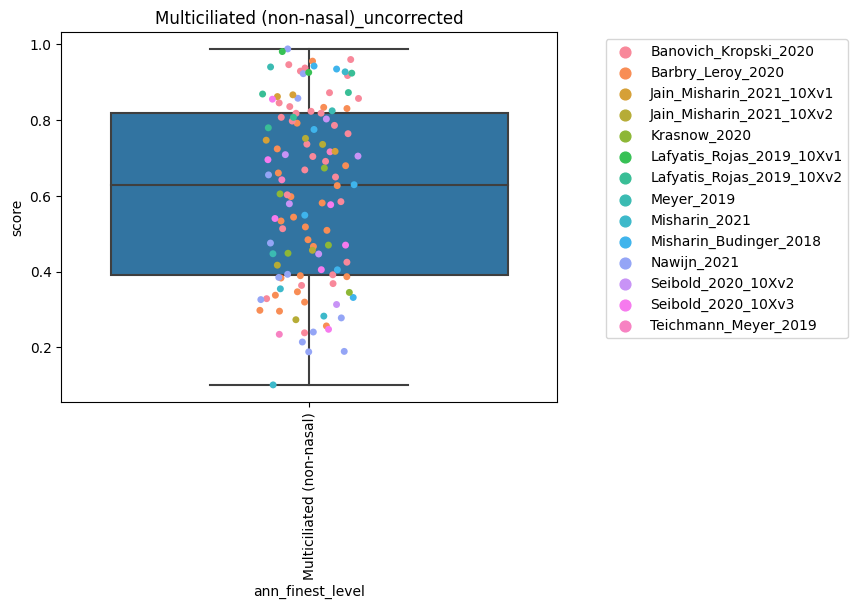

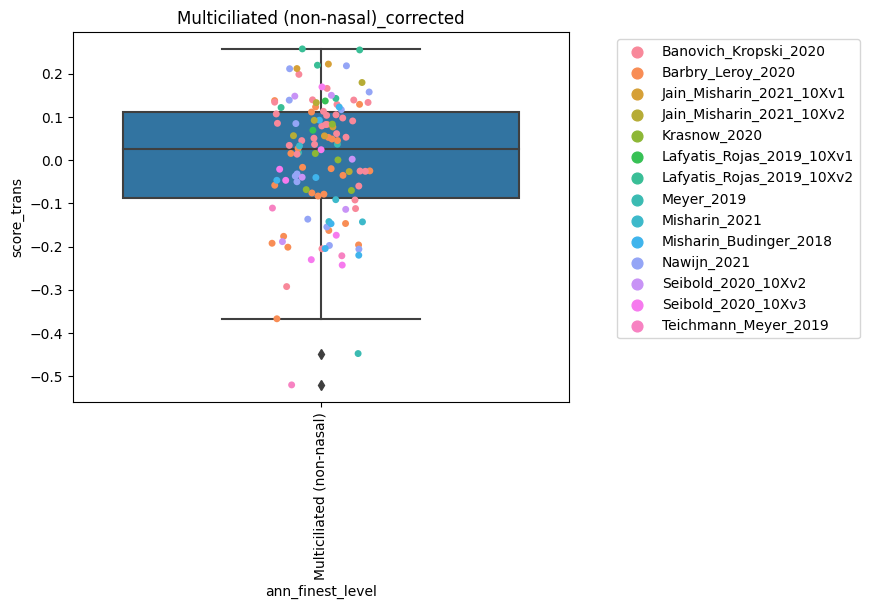

Multiciliated (non-nasal) as reference
Empty DataFrame
Columns: [cell type, p-value]
Index: []

                  percent
ann_finest_level         
NK cells            100.0


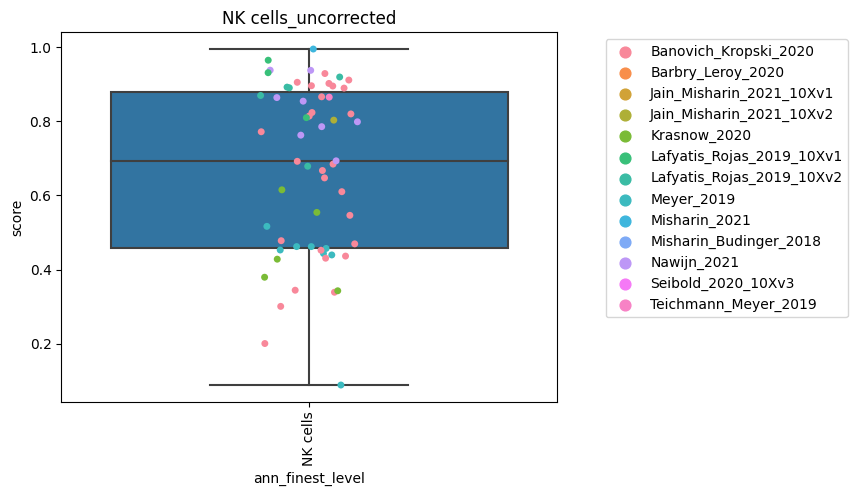

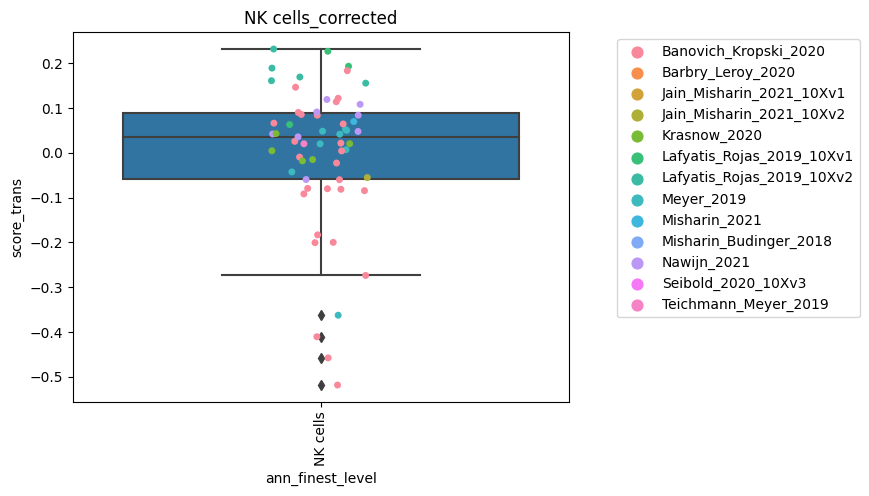

NK cells as reference
Empty DataFrame
Columns: [cell type, p-value]
Index: []

                  percent
ann_finest_level         
Suprabasal          100.0


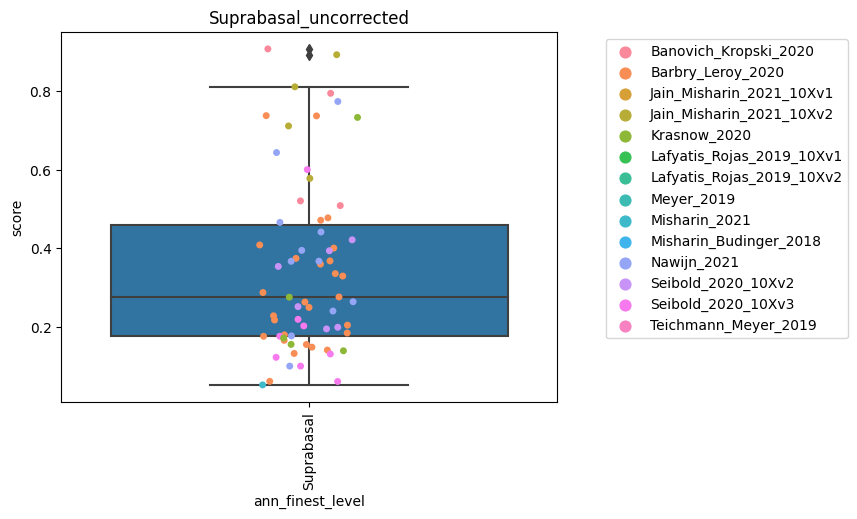

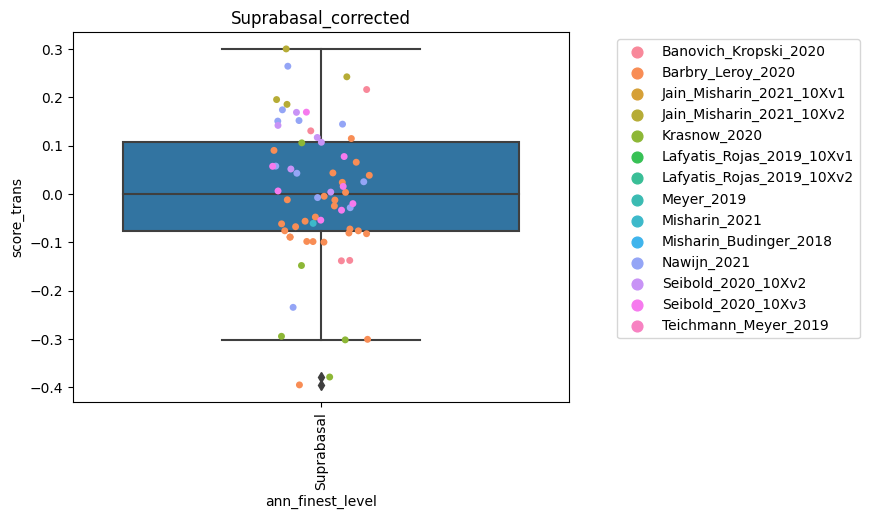

Suprabasal as reference
Empty DataFrame
Columns: [cell type, p-value]
Index: []

                        percent
ann_finest_level               
CD4 T cells            41.85100
CD8 T cells            57.16589
T cells proliferating   0.98311


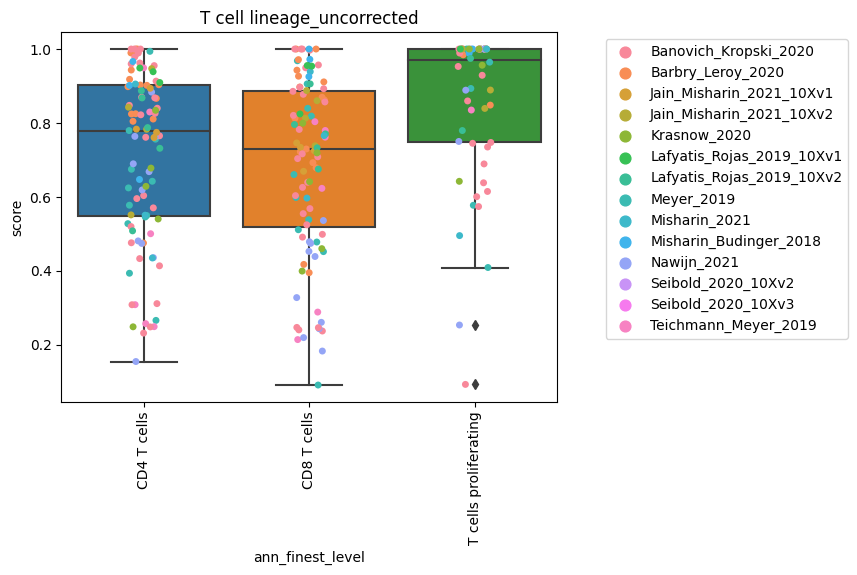

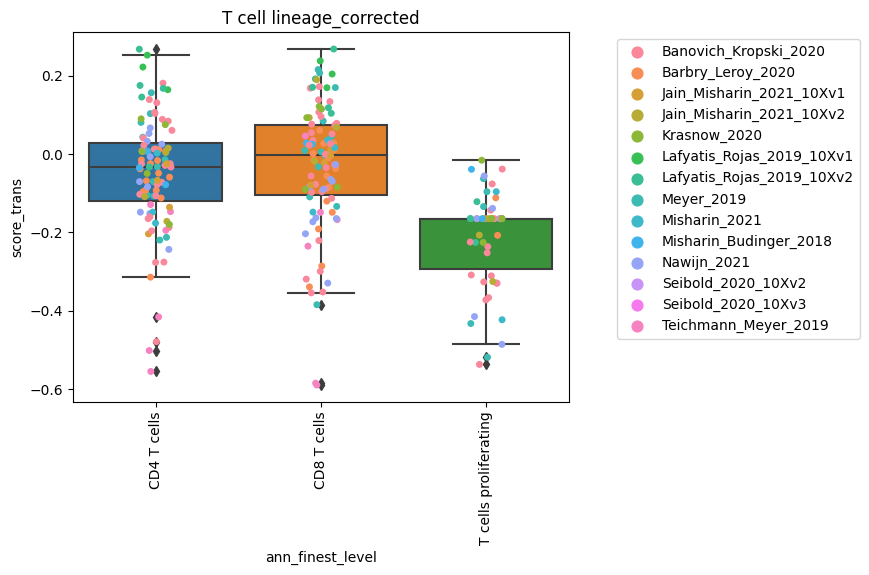

CD8 T cells as reference
               cell type  p-value
0            CD4 T cells   0.2064
1  T cells proliferating   0.0000

                    percent
ann_finest_level           
AT0               24.687125
pre-TB secretory  75.312875


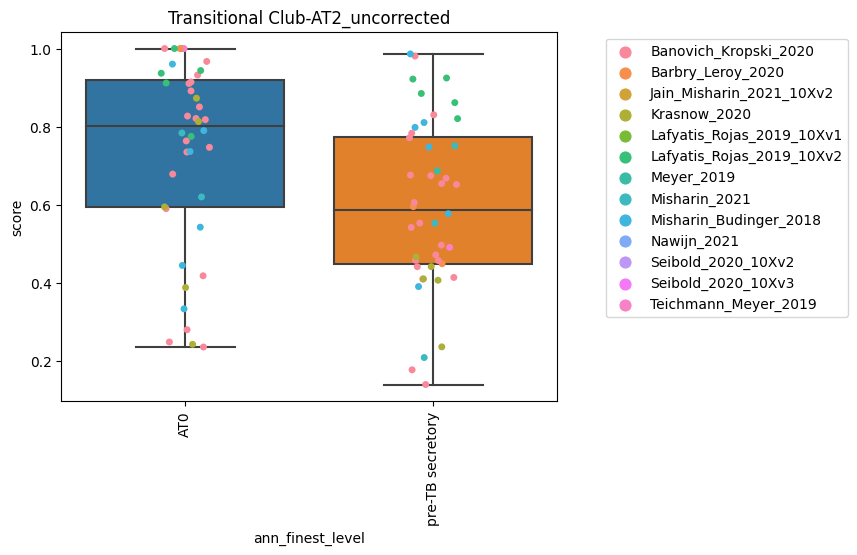

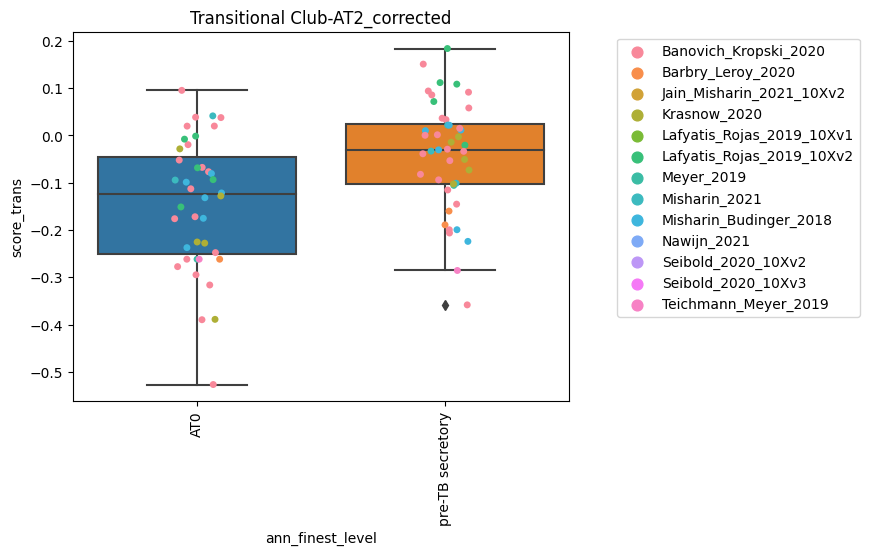

pre-TB secretory as reference
  cell type  p-value
0       AT0   0.0055



In [56]:
for cell_type in ct: 
    #get percentages of subtypes included in that cell label
    data = adata[(adata.obs.cell_label == cell_type)].obs.groupby(["ann_finest_level"]).agg({"dataset":"count"})
    percentage = (data/len(adata[(adata.obs.cell_label == cell_type)])*100).rename(columns={"dataset":"percent"})
    print(percentage)
    compare_to = percentage.idxmax().to_list()[0]
    
    
    #get corrected and uncorrected mean scores
    data = adata[(adata.obs.cell_label == cell_type)].obs.groupby(["ann_finest_level","sample"]).agg({"score":"mean","subject_ID":"count","dataset":"first"}).dropna().reset_index(drop=False)
    data["log_size"] = np.log(data["subject_ID"])
    data["score_trans"] = data["score"]-(trans.loc[cell_type].slope*data['log_size']+trans.loc[cell_type].intercept)
    data.ann_finest_level.cat.remove_unused_categories(inplace=True)
   
    sb.boxplot(data=data,x="ann_finest_level", y="score")
    sb.stripplot(data=data,x="ann_finest_level", y="score",hue="dataset")
    plt.title(f'{cell_type}_uncorrected')
    plt.xticks(rotation=90)
    plt.legend(bbox_to_anchor=(1.6, 1))
    plt.show()
    
    sb.boxplot(data=data,x="ann_finest_level", y="score_trans")
    sb.stripplot(data=data,x="ann_finest_level", y="score_trans",hue="dataset")
    plt.title(f'{cell_type}_corrected')
    plt.xticks(rotation=90)
    plt.legend(bbox_to_anchor=(1.6, 1))
    plt.show()
    
    ks_test=[]
    
    print(f'{compare_to} as reference')
    scores_compare = data[data.ann_finest_level == compare_to].score_trans.to_numpy()
    
    for finest_ct in data.ann_finest_level.cat.categories:
        if finest_ct == compare_to:
            continue
        query_scores = data[data.ann_finest_level == finest_ct].score_trans.to_numpy()
        pvalue = scipy.stats.ks_2samp(scores_compare, query_scores).pvalue
        ks_test.append((finest_ct,np.round(pvalue,4)))
    dataframe = pd.DataFrame(data=ks_test,columns=["cell type","p-value"])
    print(dataframe)
    print()

Observation: proliferating cell types most differing in mixing to their parent

Dendritic cells: smaller cell types lower mixing scores

Subpleural fibroblasts low scores even after correction and small cell counts (you would expect better scores with low cell counts)

The mixing scores do differ in the subtypes a lot (Except for EC) but is it worth going down to finer levels? Lets check how the mapping uncertainty changes from our level to the sublevels:

In [57]:
adata= sc.read(f'{workspace}\\Adatas\\HLCA_full_tranf.h5ad')

In [61]:
adata[adata.obs.query_or_reference=="query"].obs.ann_finest_level

cc05p_CATGCCTGTGTGCCTG_carraro_csmc                                     Unknown
D062_TGACCCTTCAAACCCA-sub_wang_sub_batch3                  Alveolar fibroblasts
muc9826_GTCGTGAGAGGA_mayr                             Multiciliated (non-nasal)
scrBT1428_CCACGGATCGCATGGC_lambrechts                               CD8 T cells
04-P103142-S149-R01-GCAGCCAGTACGTAGG_delorey_fresh                      Unknown
                                                                ...            
SC25_CGTGTCTTCTGCAGTA_reyfman_disease                      Alveolar macrophages
TTGTGGATCGTTCCTG_5-PX5-sub_mould                           Alveolar macrophages
CAACCTCTCATGTAGC-WSSS8015042-0_meyer_unpubl                Alveolar macrophages
022C-b_GGATGTTTCCAAGTAC_adams                                           Unknown
145I-a_GTCGTAACAGTAGAGC_adams                                           Unknown
Name: ann_finest_level, Length: 1697503, dtype: category
Categories (61, object): ['AT0', 'AT1', 'AT2', 'AT2 proliferati

In [65]:
adata

AnnData object with n_obs × n_vars = 2282447 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'ti

Next we assess how much the uncertainty changes when increasing the level. For cell types that are on their lowest level, the uncertainty should stay the same. 

In [73]:
def get_level(adata_obs,ct):
    for i in range(5,0,-1):
        if ct in adata_obs[f"transf_ann_level_{i}_label"].cat.categories:
            return i
    

AT2                      106343
Secretory                   435
Basal                       276
Macrophages                  67
Multiciliated lineage         3
Name: transf_ann_level_3_label, dtype: int64

3_AT2                      105670
AT2 proliferating            1238
3_AT1                          68
Goblet                         38
Hillock-like                   34
Suprabasal                     20
Club                           19
Transitional Club-AT2          14
Alveolar macrophages            6
Basal resting                   6
Multiciliated                   4
2_Smooth muscle                 2
Plasma cells                    2
Adventitial fibroblasts         1
EC general capillary            1
Tuft                            1
Name: transf_ann_level_4_label, dtype: int64

3_AT2                         105686
4_AT2 proliferating             1240
3_AT1                             68
Goblet (nasal)                    37
4_Hillock-like                    34
4_Suprabasal       

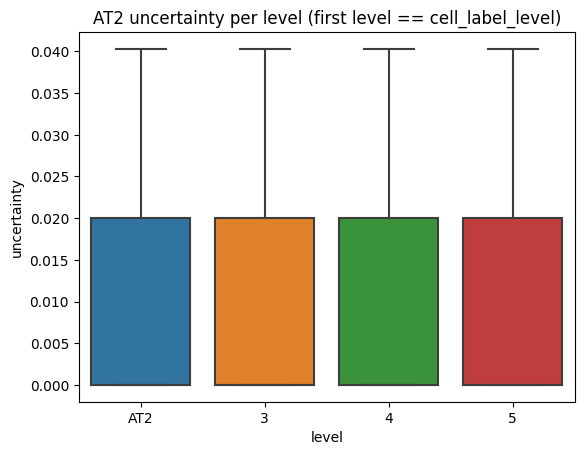

Alveolar macrophages        293676
Multiciliated                   18
Club                             6
Interstitial macrophages         1
Name: transf_ann_level_4_label, dtype: int64

4_Alveolar macrophages           266581
Alveolar Mph CCL3+                15082
Alveolar Mph proliferating         5398
Monocyte-derived Mph               3775
Alveolar Mph MT-positive           1730
4_Non-classical monocytes           400
4_DC2                               360
4_Classical monocytes               259
Interstitial Mph perivascular        21
4_CD8 T cells                        18
Club (nasal)                         17
Goblet (nasal)                       14
Multiciliated (non-nasal)             9
3_AT2                                 9
4_EC general capillary                6
4_NK cells                            5
4_Suprabasal                          4
4_Plasma cells                        3
4_CD4 T cells                         3
4_T cells proliferating               2
4_Basal restin

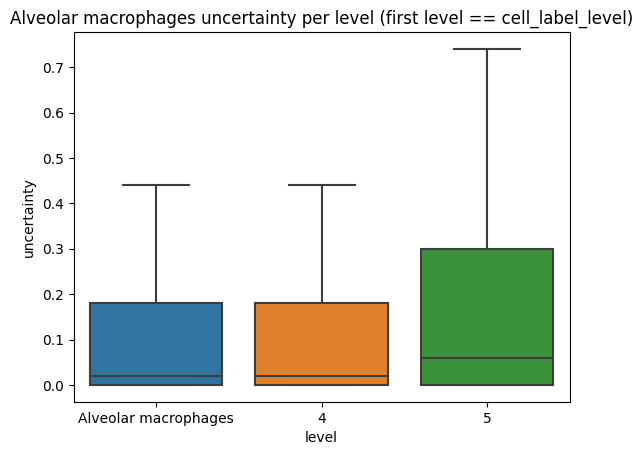

Dendritic cells    48992
Macrophages         2096
Secretory              6
Basal                  4
B cell lineage         3
Name: transf_ann_level_3_label, dtype: int64

DC2                         43258
Plasmacytoid DCs             3341
Migratory DCs                2648
DC1                          1682
B cells                        77
Interstitial macrophages       56
Alveolar macrophages           11
CD8 T cells                     9
Non-classical monocytes         4
NK cells                        4
3_AT2                           3
Classical monocytes             2
CD4 T cells                     2
EC general capillary            1
Club                            1
Plasma cells                    1
Suprabasal                      1
Name: transf_ann_level_4_label, dtype: int64

4_DC2                        43271
4_Plasmacytoid DCs            3342
4_Migratory DCs               2648
4_DC1                         1682
4_B cells                       77
Monocyte-derived Mph          

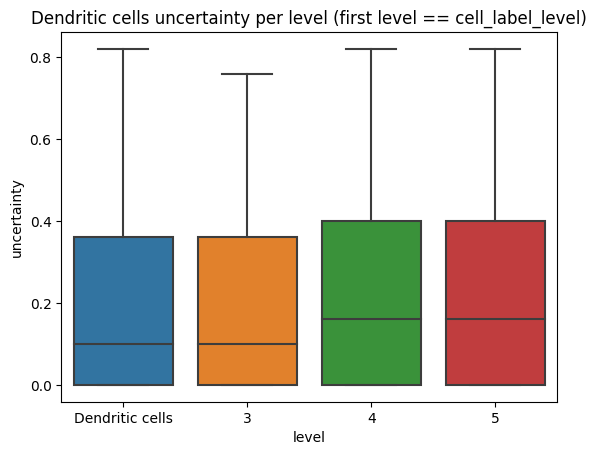

EC arterial    10380
Secretory          4
Macrophages        2
Name: transf_ann_level_3_label, dtype: int64

3_EC arterial    10384
Club                 2
Name: transf_ann_level_4_label, dtype: int64

3_EC arterial    10386
Name: transf_ann_level_5_label, dtype: int64



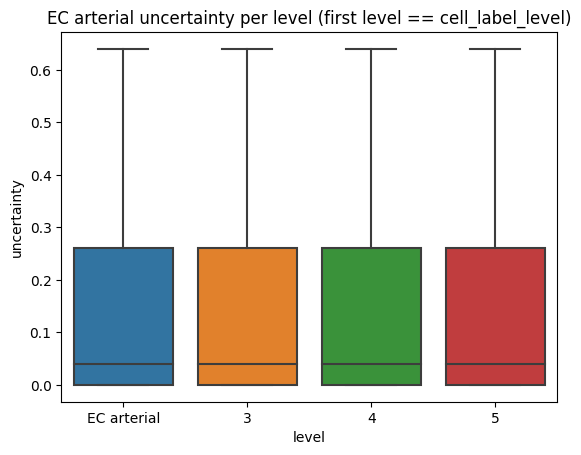

EC venous      30981
Macrophages        9
Basal              5
Name: transf_ann_level_3_label, dtype: int64

EC venous systemic                21777
EC venous pulmonary                8806
EC general capillary                273
3_EC arterial                        72
Alveolar macrophages                 18
Plasma cells                         11
Classical monocytes                   9
3_Lymphatic EC differentiating        7
Basal resting                         4
3_AT2                                 3
3_Lymphatic EC mature                 3
CD8 T cells                           3
2_Smooth muscle                       2
Interstitial macrophages              2
Pericytes                             1
2_Mesothelium                         1
Multiciliated                         1
DC2                                   1
SMG duct                              1
Name: transf_ann_level_4_label, dtype: int64

4_EC venous systemic              21777
4_EC venous pulmonary              8807
4_EC 

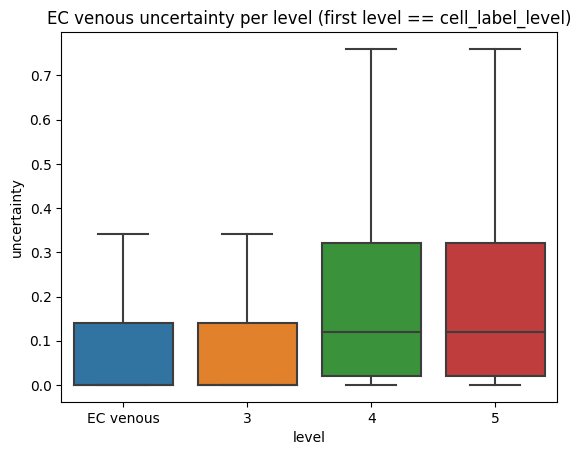

Fibroblast lineage     123617
Airway epithelium          52
Blood vessels              40
Myeloid                    30
Alveolar epithelium        12
Lymphoid                    7
Name: transf_ann_level_2_label, dtype: int64

Fibroblasts                     120470
Myofibroblasts                    3058
2_Smooth muscle                    157
Basal                               35
Secretory                           11
SM activated stress response         7
Macrophages                          6
T cell lineage                       5
B cell lineage                       4
Monocytes                            2
AT2                                  1
EC arterial                          1
EC capillary                         1
Name: transf_ann_level_3_label, dtype: int64

Alveolar fibroblasts              47857
Peribronchial fibroblasts         27923
Adventitial fibroblasts           27287
Pericytes                         12904
3_Myofibroblasts                   3763
Subpleural fibroblast

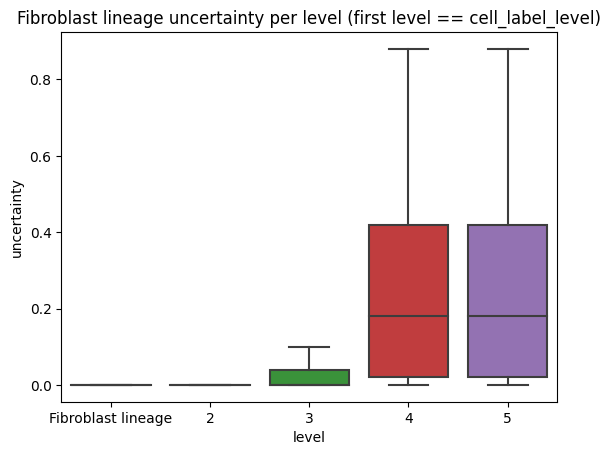

Goblet           64879
Club              1107
Multiciliated      107
Name: transf_ann_level_4_label, dtype: int64

Goblet (nasal)               61877
Goblet (bronchial)            2418
Goblet (subsegmental)          866
Club (non-nasal)               525
4_Suprabasal                   127
Club (nasal)                   104
pre-TB secretory                88
Multiciliated (non-nasal)       42
4_SMG duct                      19
4_Deuterosomal                   7
4_Basal resting                  6
3_AT2                            5
4_SMG mucous                     4
4_Plasma cells                   3
4_Alveolar macrophages           1
4_CD8 T cells                    1
Name: transf_ann_level_5_label, dtype: int64



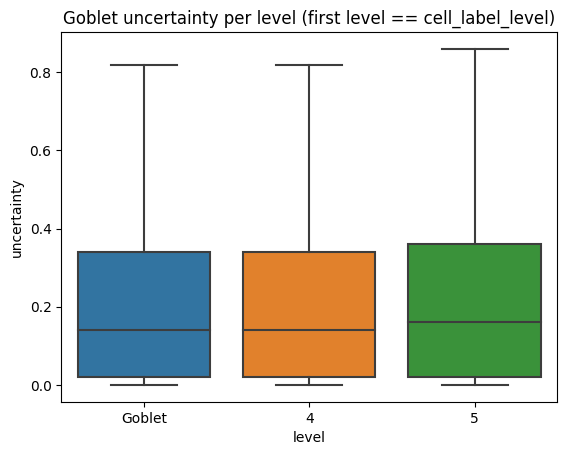

Interstitial macrophages    190213
Multiciliated                    1
Name: transf_ann_level_4_label, dtype: int64

Monocyte-derived Mph             168836
Interstitial Mph perivascular     16066
4_DC2                              2069
4_Alveolar macrophages             1704
4_Non-classical monocytes           735
4_Classical monocytes               710
Alveolar Mph CCL3+                   50
Alveolar Mph MT-positive             16
4_CD8 T cells                         6
4_NK cells                            5
4_Plasma cells                        4
Multiciliated (non-nasal)             2
3_AT2                                 2
4_EC venous pulmonary                 2
4_Plasmacytoid DCs                    1
2_Smooth muscle                       1
3_AT1                                 1
4_Basal resting                       1
4_Alveolar fibroblasts                1
3_Mast cells                          1
4_EC general capillary                1
Name: transf_ann_level_5_label, dtype: int64

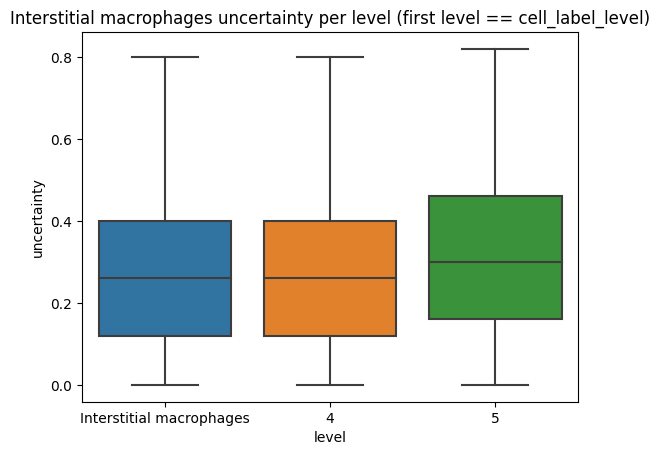

Mast cells     15169
Secretory         19
Macrophages        3
Basal              1
Name: transf_ann_level_3_label, dtype: int64

3_Mast cells    15190
Club                2
Name: transf_ann_level_4_label, dtype: int64

3_Mast cells    15192
Name: transf_ann_level_5_label, dtype: int64



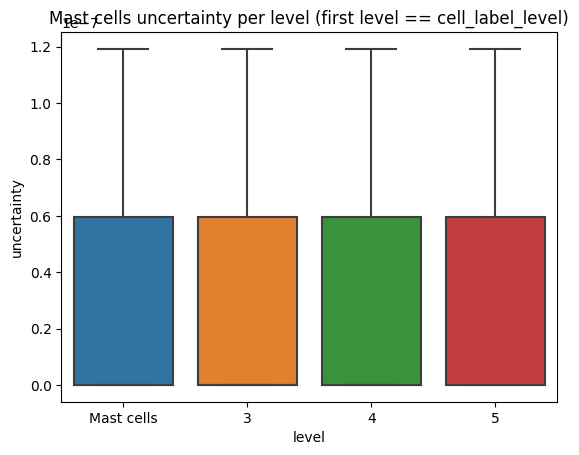

Monocytes                128359
Macrophages                6019
Secretory                    28
Basal                         6
B cell lineage                5
Multiciliated lineage         1
Name: transf_ann_level_3_label, dtype: int64

Classical monocytes         90456
Non-classical monocytes     38243
Interstitial macrophages     3282
Alveolar macrophages         1395
DC2                           895
CD8 T cells                    42
CD4 T cells                    27
B cells                        18
3_AT2                           9
2_Smooth muscle                 8
Basal resting                   7
Goblet                          6
Plasma cells                    6
3_Mast cells                    5
EC general capillary            5
Multiciliated                   5
NK cells                        3
Club                            2
Adventitial fibroblasts         1
Pericytes                       1
3_EC arterial                   1
Suprabasal                      1
Name: transf_a

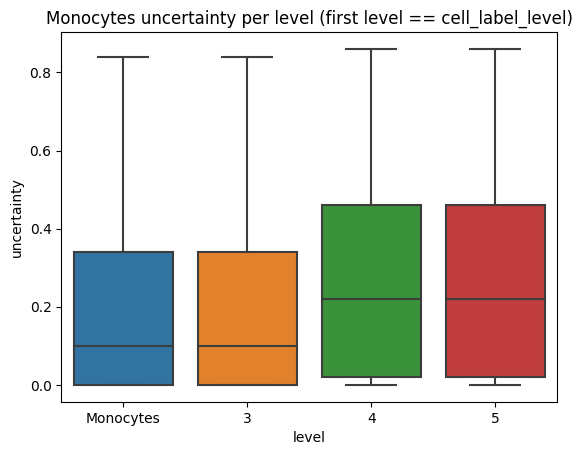

Multiciliated (non-nasal)    85021
Name: transf_ann_level_5_label, dtype: int64



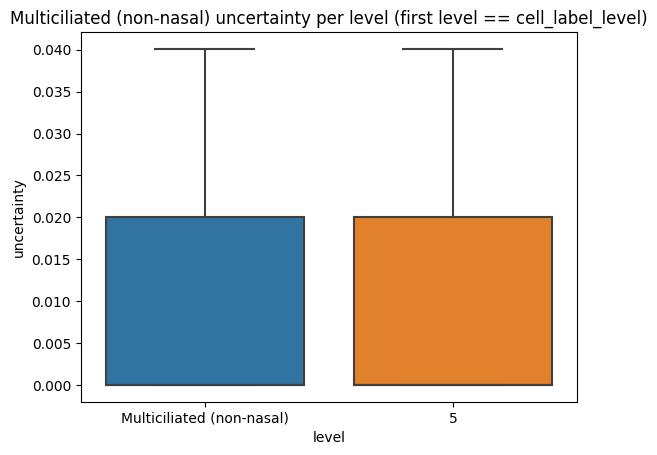

NK cells         38032
CD8 T cells          1
Multiciliated        1
Name: transf_ann_level_4_label, dtype: int64

4_NK cells       38033
4_CD8 T cells        1
Name: transf_ann_level_5_label, dtype: int64



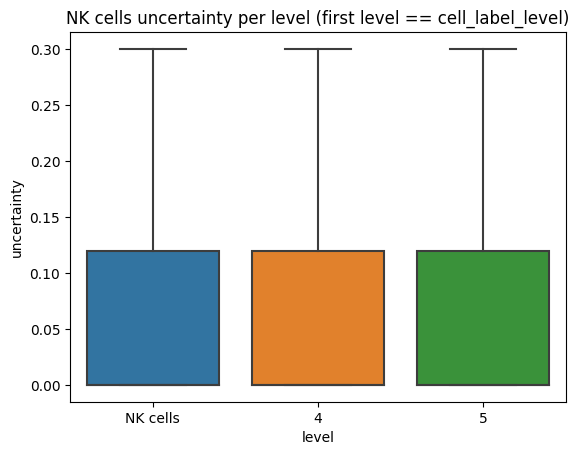

Suprabasal    38897
Club            316
Name: transf_ann_level_4_label, dtype: int64

4_Suprabasal    39213
Name: transf_ann_level_5_label, dtype: int64



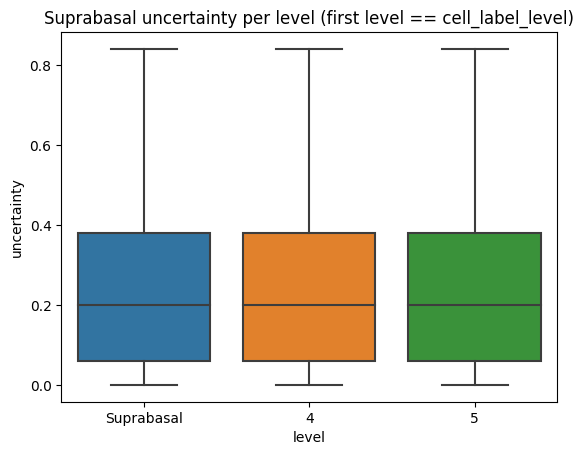

T cell lineage           207666
Macrophages                 159
B cell lineage              107
Secretory                    62
Basal                        19
Multiciliated lineage         8
Name: transf_ann_level_3_label, dtype: int64

CD8 T cells                   117954
CD4 T cells                    84085
T cells proliferating           5157
B cells                          141
Plasma cells                     129
NK cells                         123
Alveolar macrophages             111
Interstitial macrophages          50
Classical monocytes               46
Club                              40
3_AT2                             26
Basal resting                     22
Non-classical monocytes           20
3_Mast cells                      19
Multiciliated                     19
DC2                               16
3_AT1                             12
EC general capillary              12
Goblet                             8
Suprabasal                         5
EC venous systemic    

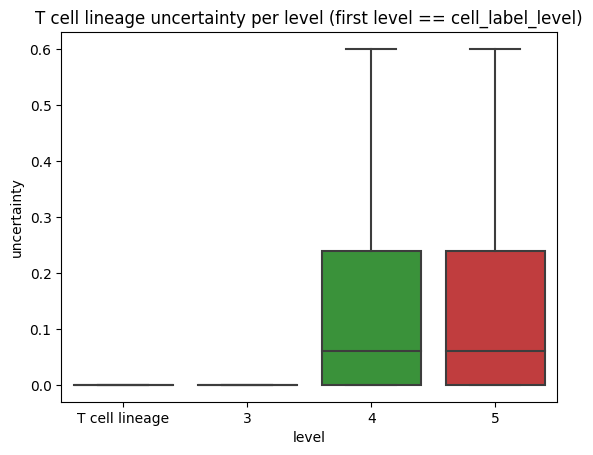

Transitional Club-AT2    17098
Club                        22
Name: transf_ann_level_4_label, dtype: int64

pre-TB secretory             13573
AT0                           2928
3_AT2                          366
Goblet (nasal)                 144
3_AT1                           30
4_Basal resting                 27
Club (non-nasal)                22
4_Suprabasal                    10
Multiciliated (non-nasal)        9
Club (nasal)                     3
3_EC arterial                    2
4_SMG duct                       2
4_CD4 T cells                    1
4_CD8 T cells                    1
4_Classical monocytes            1
Goblet (bronchial)               1
Name: transf_ann_level_5_label, dtype: int64



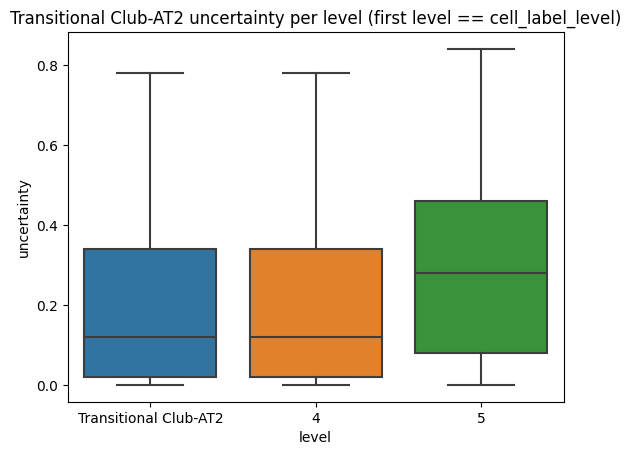

In [117]:
for cell_type in ct: 
    #get uncertainties per sublevel
    adata_sub_obs = adata[(adata.obs.cell_label == cell_type)&(adata.obs.query_or_reference=="query")].obs
    main_uncert = adata[(adata.obs.cell_label == cell_type)&(adata.obs.query_or_reference=="query")].obs.cell_label_uncert.to_numpy()
    uncert_list=[(cell_type,main_uncert)]
    start_lvl = get_level(adata_sub_obs,cell_type)
    for lvl in range(start_lvl,6,1):
        #first one should be more or less identical to cell_label_uncert
        print(adata_sub_obs[f"transf_ann_level_{lvl}_label"].value_counts())
        print()
        uncert = adata_sub_obs[f"transf_ann_level_{lvl}_uncert"].to_numpy()
        uncert_list.append((lvl,uncert))
    df = pd.DataFrame(uncert_list,columns=("level","uncertainty"))
    df = df.explode("uncertainty")
    sb.boxplot(data=df,x="level",y="uncertainty",showfliers=False)
    plt.title(f"{cell_type} uncertainty per level (first level == cell_label_level)")
    plt.show()

Even though the mixing score distributions of the sub-cell types differ, the uncertainty rises for cell types such as Monocytes, Fibroblasts and T cells.
For the Macrophages (both types) and Dendritic cells and Goblet cells the rise is not very steep. Possibly allowing for higher levels to be introduced.

